<a href="https://colab.research.google.com/github/azhongai666/AI_code_pulich/blob/main/261109_%E4%BD%BF%E7%94%A8YOLO26_%E8%BF%9B%E8%A1%8C%E9%AB%98%E5%88%86%E8%BE%A8%E7%8E%87%E5%88%87%E7%89%87%E9%A2%84%E6%B5%8B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 使用 Ultralytics YOLO26 进行高分辨率切片

本笔记本演示如何借助 Ultralytics 的 `tile` 参数，在大尺寸图像和视频中检测小目标。各任务与全部选项请参见[高分辨率切片指南](https://docs.ultralytics.com/guides/high-resolution-tiling)。

### 什么是切片？

YOLO26 会把每张图像的最长边缩放到 `imgsz`（默认 640），因此大图中的小目标可能被压缩到只剩几个像素。使用 `tile=True` 时，Ultralytics 会把每张图像切分为相互重叠的窗口，在每个窗口上运行模型，再把检测结果合并回每张原始图像对应的单个结果。

- **内置支持：** `tile` 可用于 `predict`、`track`、`val` 和 `train`，无需额外安装任何包。
- **尺寸设置简单：** `tile=True` 用 `imgsz` 作为窗口大小，整数如 `tile=1024` 则可单独指定窗口尺寸。窗口之间重叠 20%。小于 `imgsz` 的窗口（如 `tile=400`）会被放大到模型输入尺寸，这在目标只有几个像素宽时很有帮助。窗口过小也可能把背景杂波放大成误报。
- **权衡：** 每个窗口都意味着一次额外的模型前向计算，而且每个窗口看到的场景范围更小，因此请在自己的数据上对比切片与整图的推理结果。


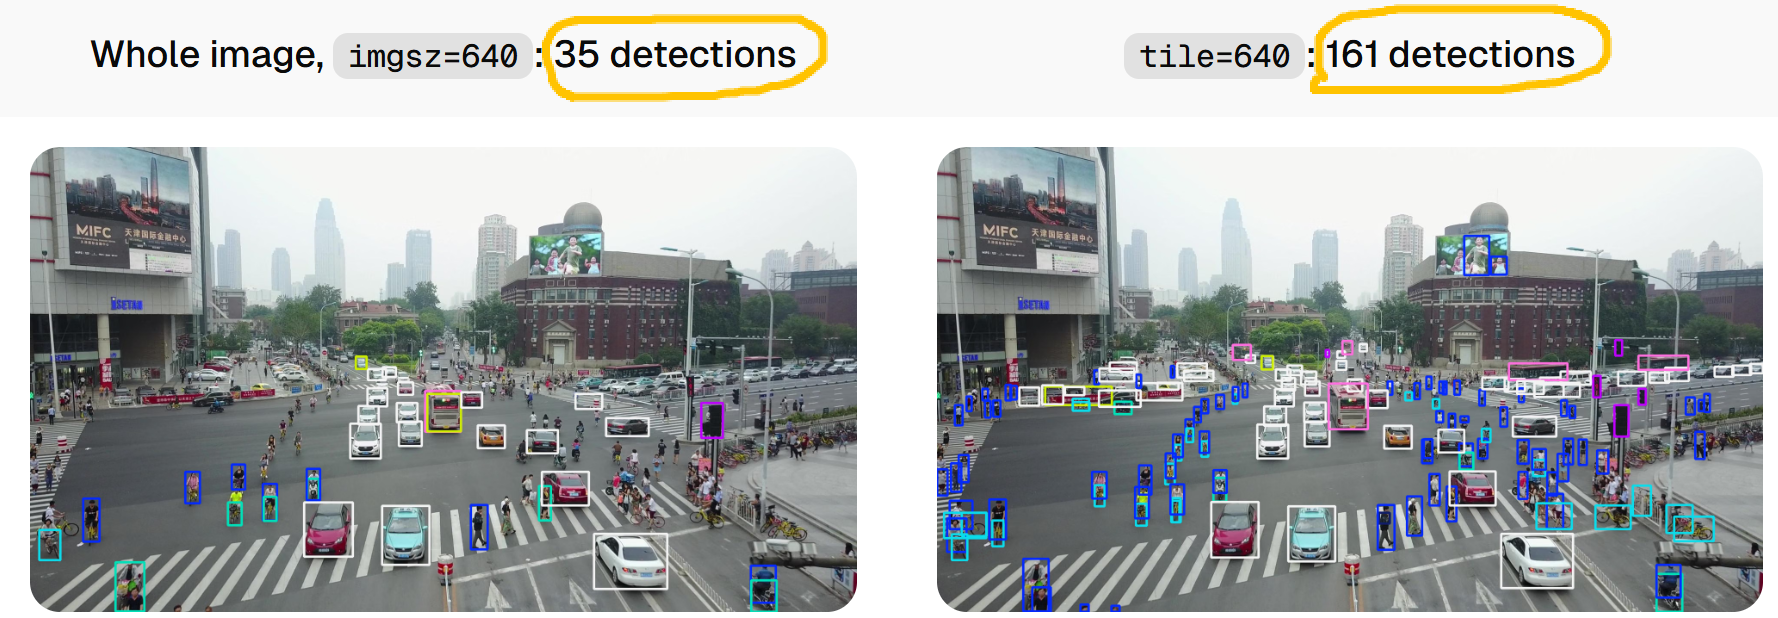

# 安装ultrlytics

In [1]:
!uv pip install ultralytics

Using Python 3.13.16 environment at: /usr
Resolved 58 packages in 553ms
Prepared 3 packages in 96ms
Installed 3 packages in 10ms
 + ultralytics==8.4.208
 + ultralytics-platform==0.1.107
 + ultralytics-thop==2.2.5


In [2]:

import ultralytics
ultralytics.checks()

Ultralytics 8.4.208 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.1/112.6 GB disk)


# 下载数据
这段 960 × 1080 的环岛航拍视频中挤满了小汽车。如果你想使用自己的图像或视频，可以跳过本步骤。

In [3]:
from ultralytics.utils.downloads import safe_download

safe_download("https://github.com/ultralytics/assets/releases/download/v0.0.0/sahi.demo.video.mp4", file="roundabout.mp4")

PosixPath('roundabout.mp4')

# 对比整图预测与切片预测

这一帧只有 960 × 1080，因此 `tile=True` 切出的 640 像素窗口是以车辆的原生尺寸呈现的，仅为整图推理中车辆尺寸的 1.7 倍。而使用 `tile=400` 时，每个 400 像素窗口会被放大 1.6 倍到 640 像素的模型输入尺寸，小尺寸停放车辆因此变得足够大而能被检出。对首帧运行两次 YOLO26s：一次整帧推理，一次使用 `tile=400`。

In [4]:
import cv2

from ultralytics import YOLO

model = YOLO("yolo26s.pt")

cap = cv2.VideoCapture("roundabout.mp4")
_, frame = cap.read()
cap.release()

whole = model.predict(frame, verbose=False)[0]
tiled = model.predict(frame, tile=400, verbose=False)[0]

In [5]:

print(f"Whole image: {len(whole.boxes)} detections, tiled: {len(tiled.boxes)} detections")

Whole image: 43 detections, tiled: 96 detections


# 结果显示

## 单图显示

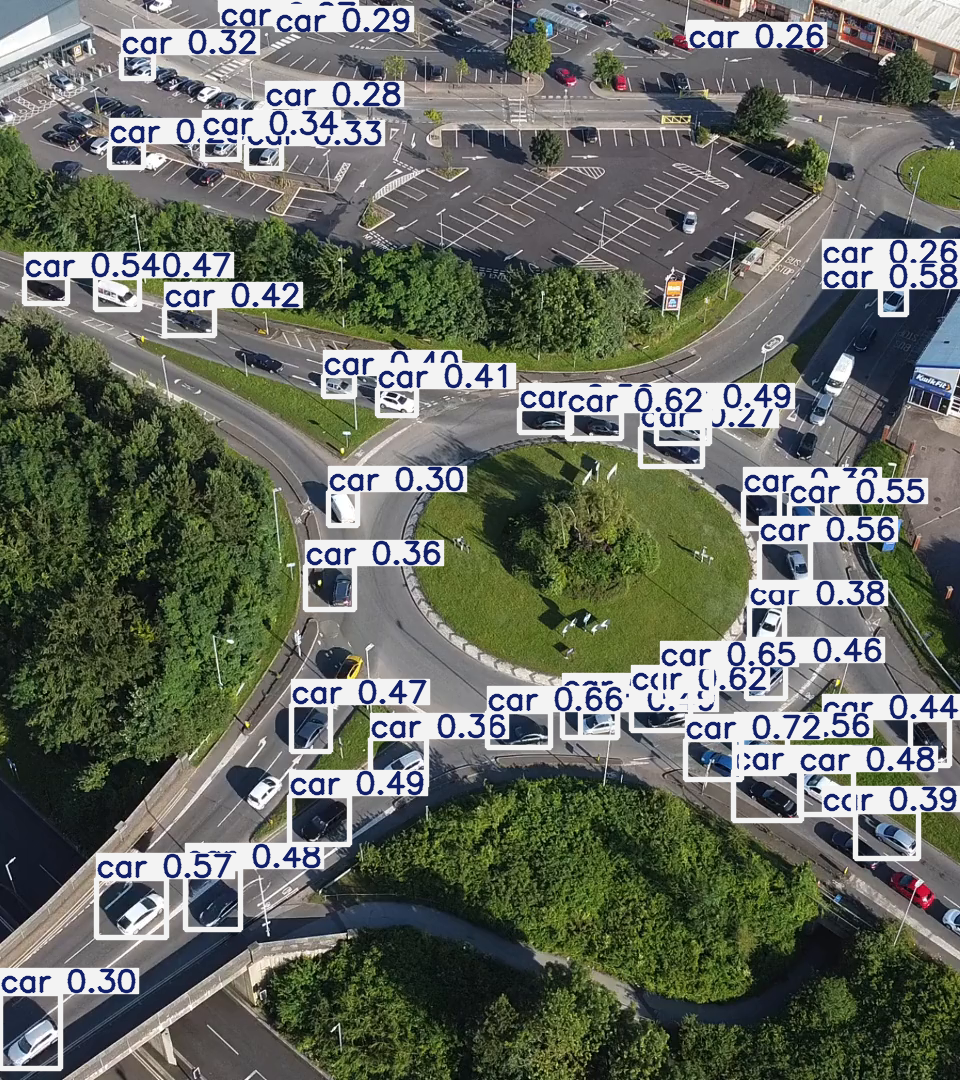

In [6]:
whole.show()

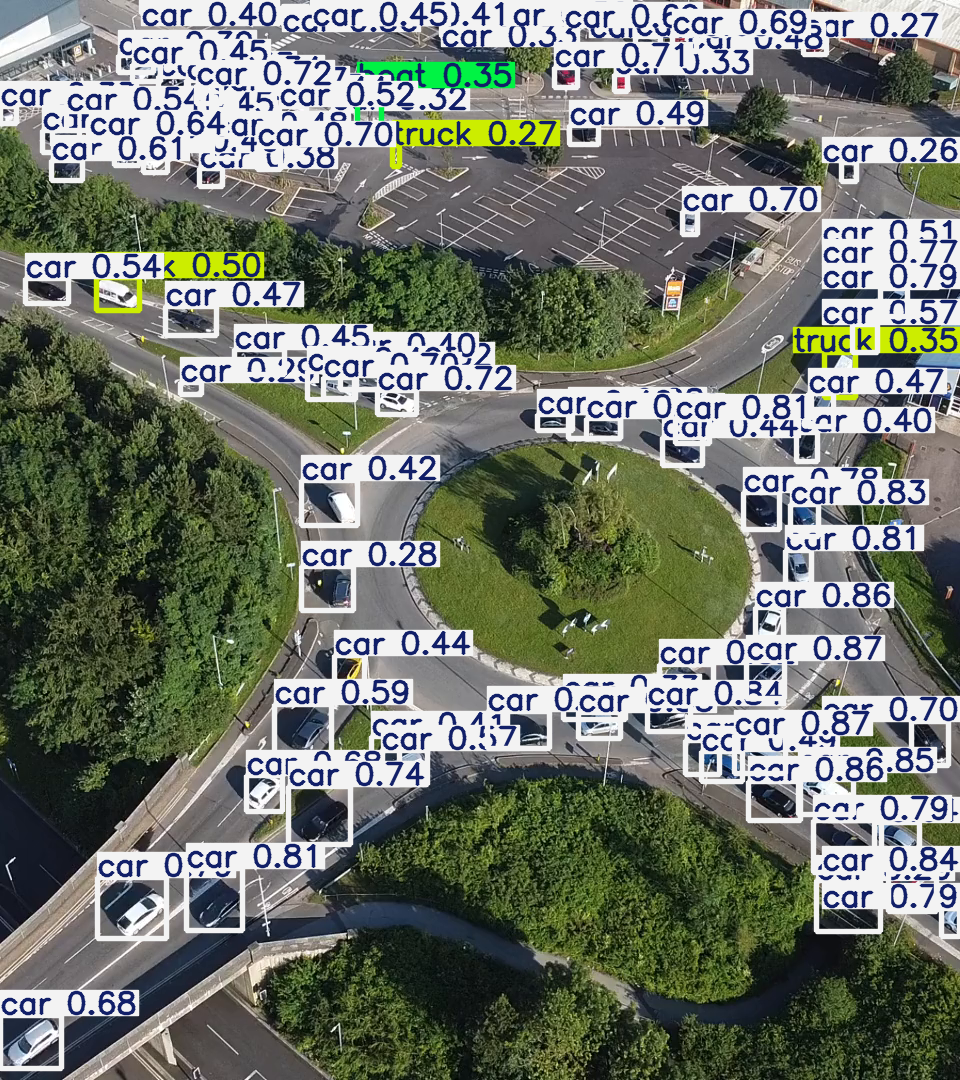

In [7]:

tiled.show()

## 对比显示

<p align="center">
  <img width="1024" src="https://cdn.ul.run/i/d6e96fdf102af52175bee1612771b4df.avif" alt="YOLO26s on an aerial roundabout frame: 45 detections on the whole image (left) and 102 with tile=400 (right)">
</p>

在这一帧上，YOLO26s 整图返回 45 个检测结果，使用 `tile=400` 时为 102 个；其中左上角停车场的检测数从 6 个提升到 31 个。

# 视频切片预测

使用 `stream=True` 逐帧处理视频，以限制内存占用。`save=True` 会把标注后的视频写入 `runs/detect/predict`，`batch` 设置同时运行的窗口数量。使用 `tile=400` 时，每帧会拆成 12 个窗口运行，因此处理完整视频请使用 GPU 运行时。


In [8]:
counts = [len(r.boxes) for r in model.predict("roundabout.mp4", tile=400, stream=True, save=True, verbose=False)]
print(f"{len(counts)} frames, {sum(counts) / len(counts):.1f} detections per frame on average")

Results saved to /content/runs/detect/predict
450 frames, 89.2 detections per frame on average


同样的选项也可在命令行中使用：

```bash
yolo predict model=yolo26s.pt source=roundabout.mp4 tile=400 save=True
```

若要在帧与帧之间跟踪每一辆车，使用 `model.track("roundabout.mp4", tile=400)`。跟踪器会在每帧合并后的检测结果上运行一次。


# 注意事项

### 使用切片进行训练与验证

当图像尺寸远大于 `imgsz` 时，训练和验证应使用相同的 `tile` 设置。训练会把每张图像切成窗口，在窗口边缘裁剪标注，并把空窗口保留为负样本。验证会先合并切片预测结果，再对原始标注计算评分。

```python
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
model.train(data="VisDrone.yaml", tile=True, imgsz=640, epochs=100)
metrics = model.val(data="VisDrone.yaml", tile=True, imgsz=640)
```

VisDrone 数据集约需下载 2 GB，因此这里的示例未实际运行。支持的任务、内存与质量方面的说明请参见[高分辨率切片指南](https://docs.ultralytics.com/guides/high-resolution-tiling)。
